# **Linear Regression**


Linear Regression is a method to find a relationship between input variables (features) and an output variable (target).

***Importing Basic Libraries***

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

**How can we load it in Python using pandas and see the first few rows?**.

In [ ]:
df=pd.read_csv('Food_Delivery_Times.csv',sep=',')
df.head(1)

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43


## Exploring the Data**

Check your dataset by some of the commands to quickly see its size, column names, missing values, and basic statistics.

In [ ]:
df.shape

(1000, 9)

In [ ]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [ ]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [ ]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,30
Traffic_Level,30
Time_of_Day,30
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,30
Delivery_Time_min,0


In [ ]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


### Handling Null Values
Fill the missing values in the categorical columns by replacing them with the most frequent value in each column.

In [ ]:
cat_cols=['Weather','Traffic_Level','Time_of_Day']
for col in cat_cols:
  df[col]=df[col].fillna(df[col].mode()[0])

<Axes: xlabel='Courier_Experience_yrs', ylabel='Count'>

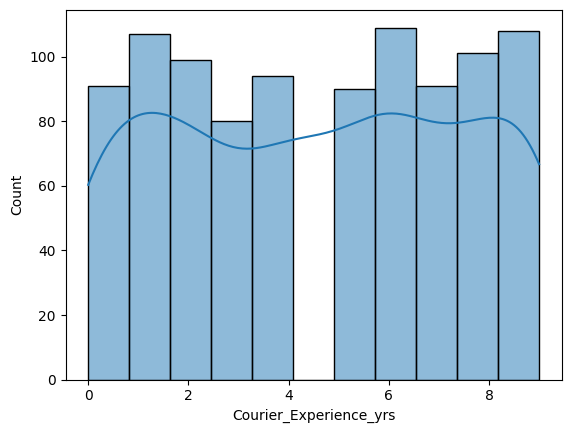

In [ ]:
sns.histplot(df['Courier_Experience_yrs'],kde=True)

In [ ]:
df['Courier_Experience_yrs']=df['Courier_Experience_yrs'].fillna(df['Courier_Experience_yrs'].median())

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 1000 non-null   object 
 3   Traffic_Level           1000 non-null   object 
 4   Time_of_Day             1000 non-null   object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  1000 non-null   float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [ ]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Weather,0
Traffic_Level,0
Time_of_Day,0
Vehicle_Type,0
Preparation_Time_min,0
Courier_Experience_yrs,0
Delivery_Time_min,0


## Visualizing the Data
Visualize the relationships between all pairs of variables in the dataset to see patterns and correlations.

In [ ]:
df.head(10)


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68
5,679,19.40,Clear,Low,Evening,Scooter,8,9.0,57
6,627,9.52,Clear,Low,Morning,Bike,12,1.0,49
7,514,17.39,Clear,Medium,Evening,Scooter,5,6.0,46
8,860,1.78,Snowy,Low,Evening,Car,20,6.0,35
9,137,10.62,Foggy,Low,Evening,Scooter,29,1.0,73


In [ ]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [ ]:
cat=['Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type']
for col in cat:
  print(df[col].value_counts())

Weather
Clear    500
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64
Traffic_Level
Medium    420
Low       383
High      197
Name: count, dtype: int64
Time_of_Day
Morning      338
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64
Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


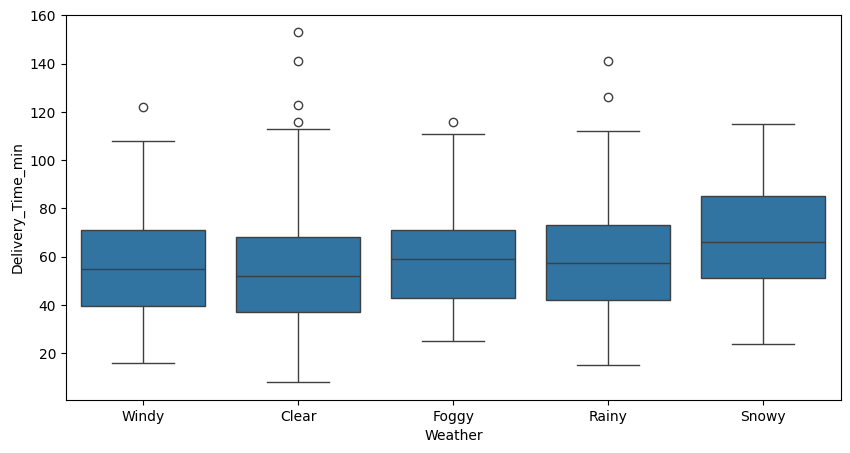

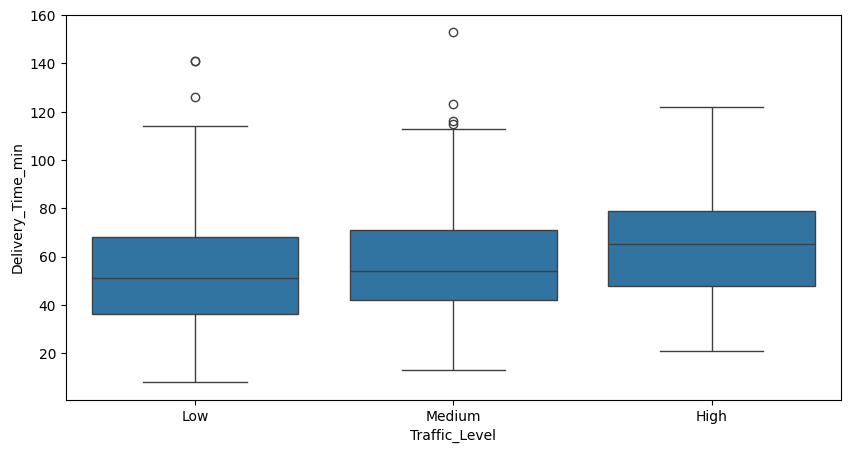

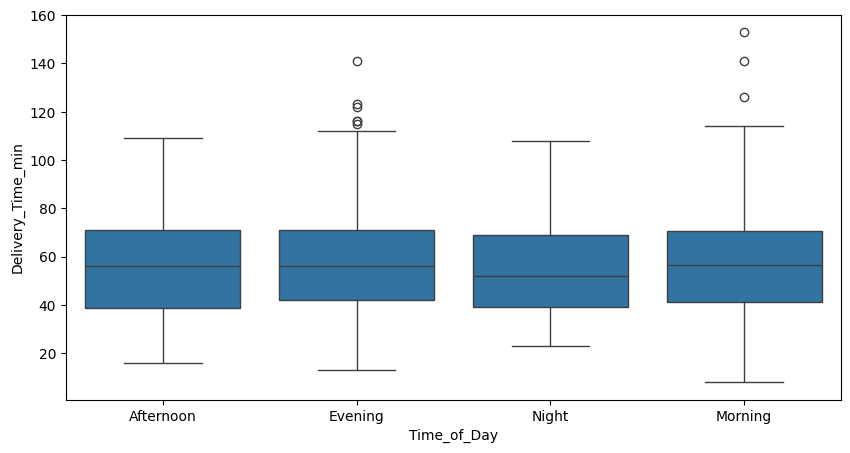

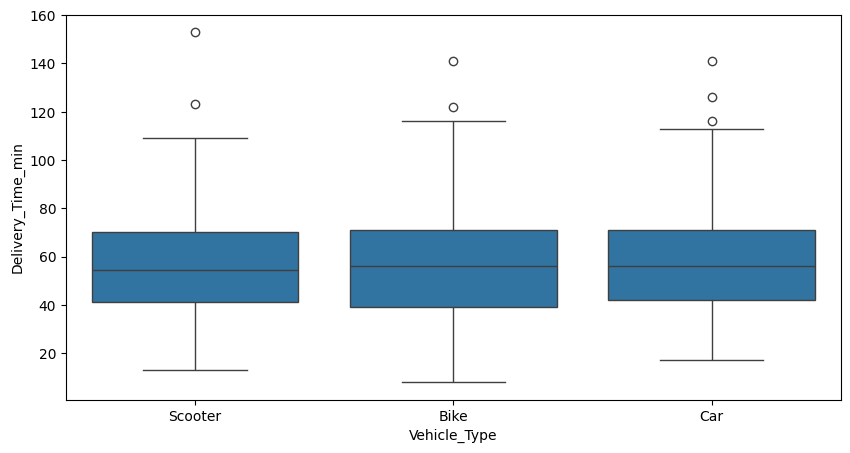

In [ ]:
for col in cat:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=col,y='Delivery_Time_min',data=df)

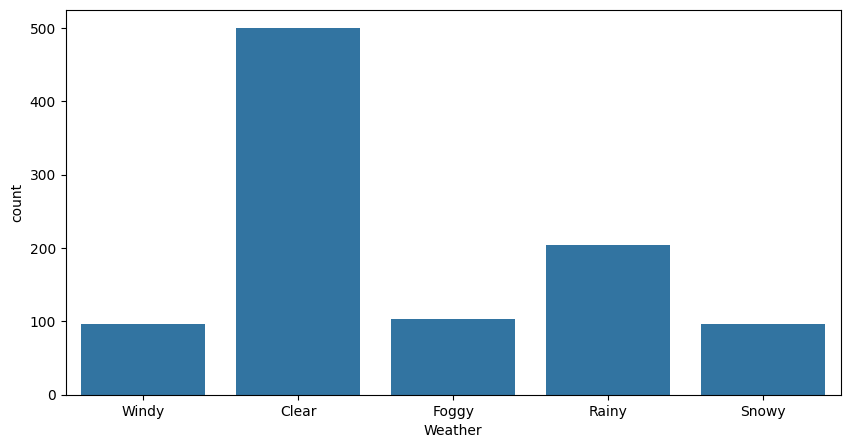

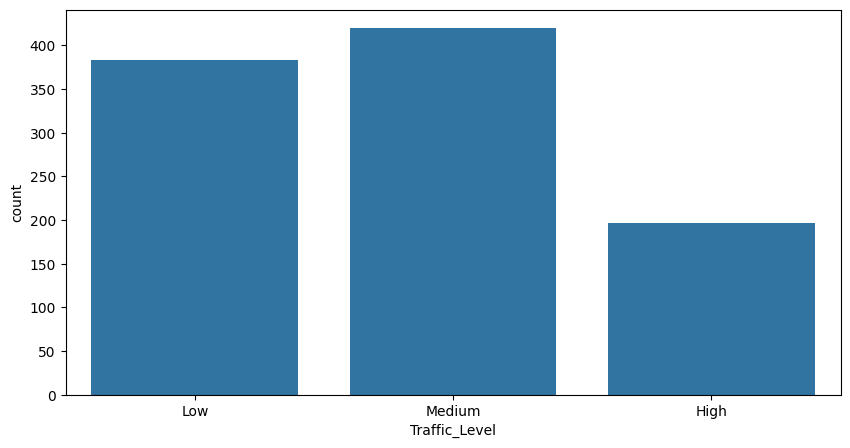

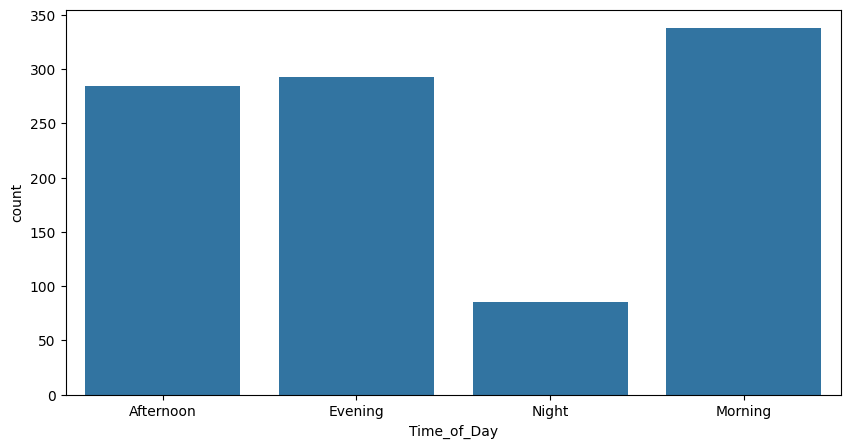

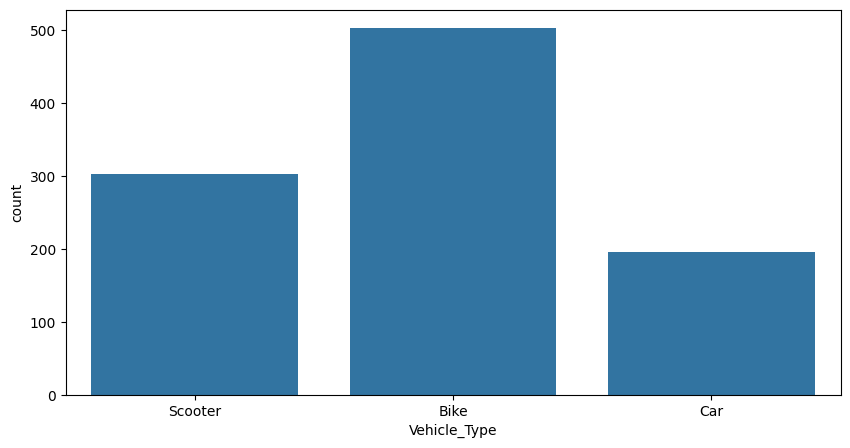

In [ ]:
for col in cat:
  plt.figure(figsize=(10,5))
  sns.countplot(x=col,data=df)

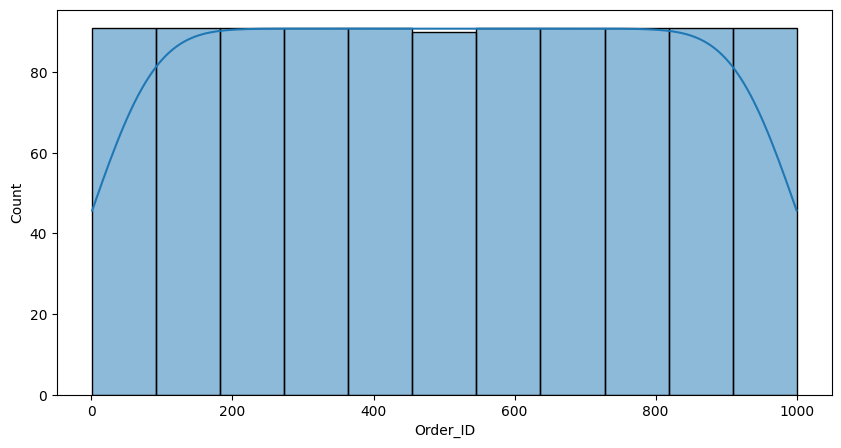

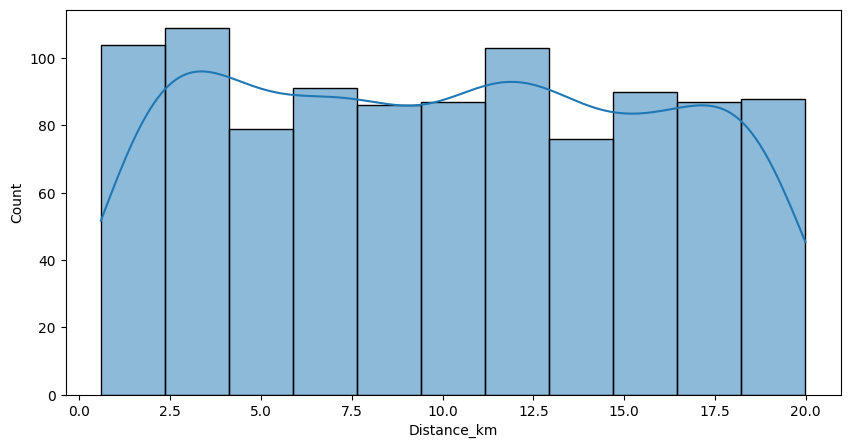

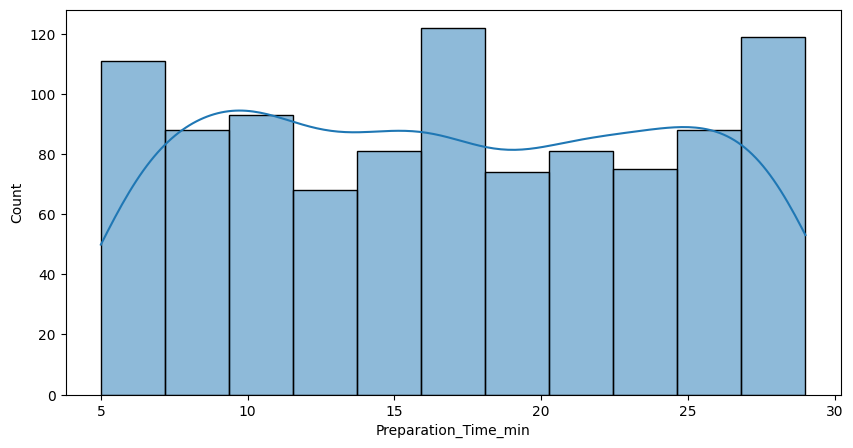

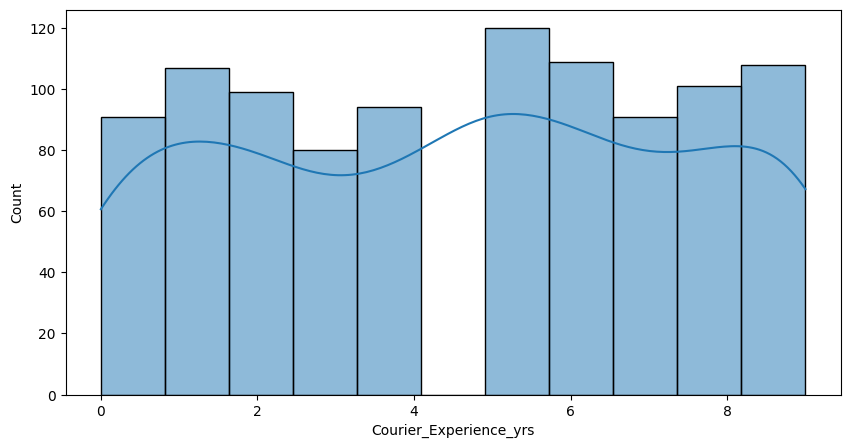

In [ ]:
cols=['Order_ID', 'Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

for col in cols:
  plt.figure(figsize=(10,5))
  sns.histplot(df[col],kde=True)

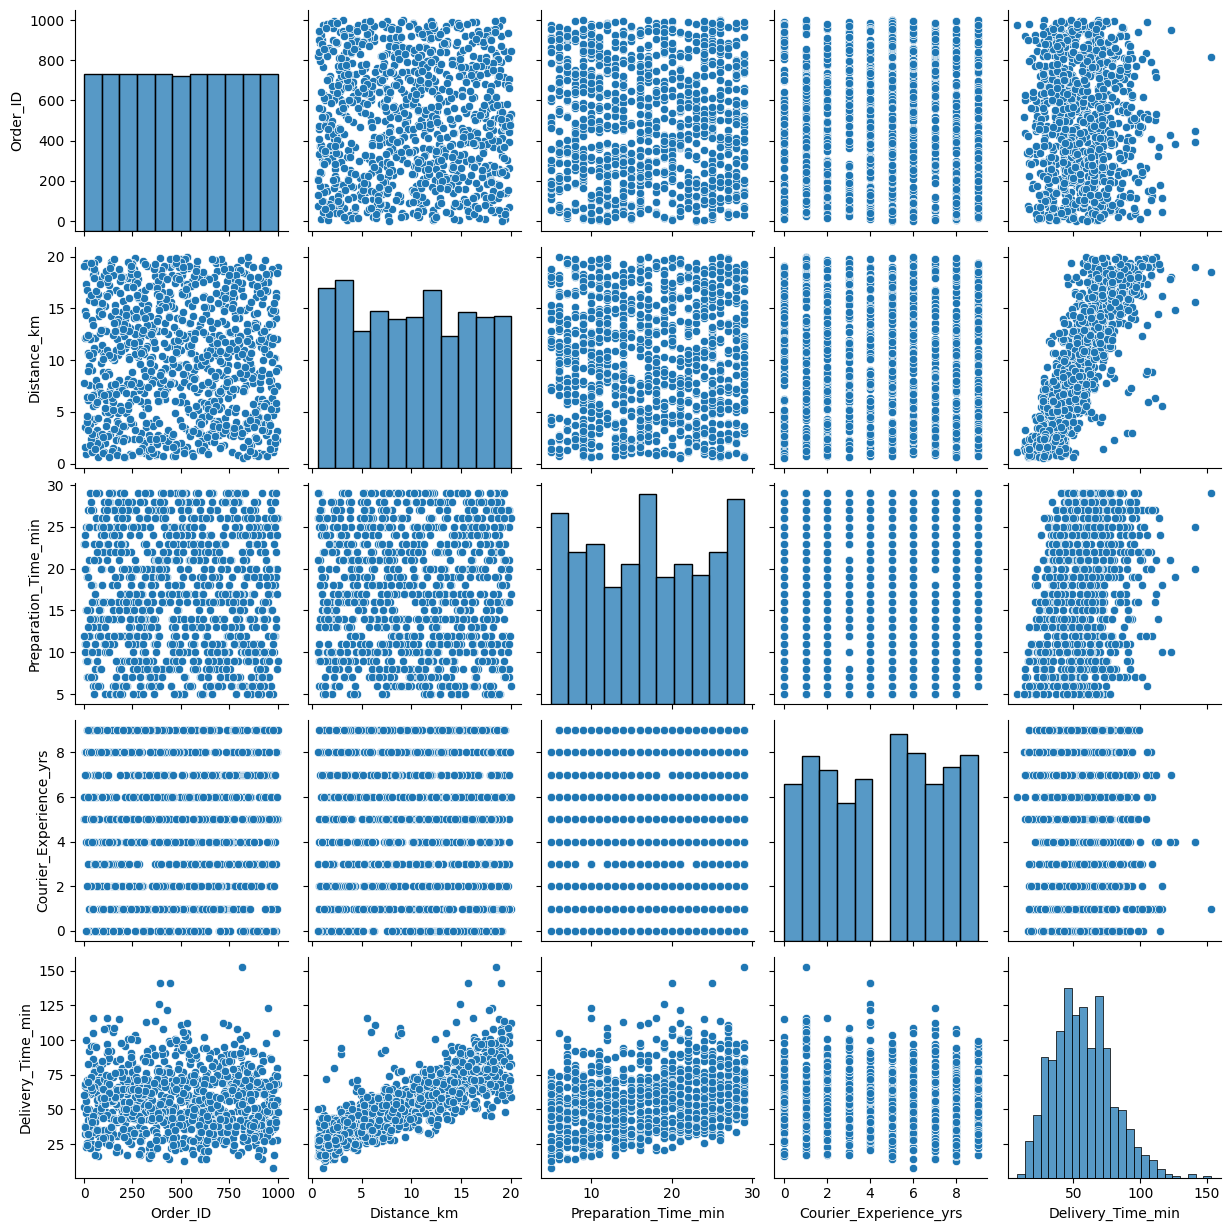

In [ ]:
sns.pairplot(df)

### Mapping Values
Linear Regression works only on numeric data, so we need to convert categorical columns into numbers.

In [ ]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df_copy=df.copy()
for col in cat:
  df[col]=le.fit_transform(df[col])

In [ ]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,4,1,0,2,12,1.0,43
1,738,16.42,0,2,1,0,20,2.0,84
2,741,9.52,1,1,3,2,28,1.0,59
3,661,7.44,2,2,0,2,5,1.0,37
4,412,19.03,0,1,2,0,16,5.0,68


In [ ]:
df_dummies=pd.get_dummies(df_copy,columns=cat)

In [ ]:
df_dummies=df_dummies.astype(int)

In [ ]:
df_dummies

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Weather_Clear,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy,Traffic_Level_High,Traffic_Level_Low,Traffic_Level_Medium,Time_of_Day_Afternoon,Time_of_Day_Evening,Time_of_Day_Morning,Time_of_Day_Night,Vehicle_Type_Bike,Vehicle_Type_Car,Vehicle_Type_Scooter
0,522,7,12,1,43,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1
1,738,16,20,2,84,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0
2,741,9,28,1,59,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1
3,661,7,5,1,37,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1
4,412,19,16,5,68,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,107,8,13,3,54,1,0,0,0,0,1,0,0,0,1,0,0,0,1,0
996,271,16,8,9,71,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1
997,861,15,26,2,81,0,0,0,1,0,1,0,0,0,1,0,0,0,0,1
998,436,14,8,0,55,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0


## **Defining Features and Target**

X (features) → known factors (distance, traffic, weather, etc.)

y (target) → what we want to predict (delivery time)


In [ ]:
x_encoded=df.drop(['Delivery_Time_min','Order_ID'],axis=1)
y_encoded=df['Delivery_Time_min']
x_dummies=df_dummies.drop(['Delivery_Time_min','Order_ID'],axis=1)
y_dummies=df_dummies['Delivery_Time_min']

## Splitting Data into Train and Test Sets**

How can we check how well our model performs on unseen data?
Why do we split the dataset into two parts:

Training set (80%) → used to train the model

Testing set (20%) → used to evaluate the modelbrary.


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test,y_train,y_test=train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model_encoded=LinearRegression()
model_encoded.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_pred=model_encoded.predict(x_test)

In [ ]:
from sklearn.metrics import mean_squared_error,r2_score

mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
n=df.shape[0]
p=df.shape[1]
adjusted_r2=1-((1-r2)*(n-1))/(n-p-1)

In [ ]:
adjusted_r2

0.7541285368687599

In [ ]:
r2

0.7563435950951675

In [ ]:
x2_train, x2_test,y2_train,y2_test=train_test_split(x_dummies, y_dummies, test_size=0.2, random_state=42)

In [ ]:
model_dummies=LinearRegression()
model_dummies.fit(x2_train,y2_train)

LinearRegression()

In [ ]:
y2_pred=model_dummies.predict(x2_test)
from sklearn.metrics import mean_squared_error,r2_score

mean_squared_error(y2_test,y2_pred)
r2=r2_score(y2_test,y2_pred)
n=df_dummies.shape[0]
p=df_dummies.shape[1]
adjusted_r2=1-((1-r2)*(n-1))/(n-p-1)


In [ ]:
adjusted_r2

0.8159135283020287

In [ ]:
r2

0.8195989431508369

## Training the Linear Regression Model**


## Making Predictions

Use the trained model to predict delivery times for the test data.

In [ ]:
y_pred=model_dummies.predict(x2_test)

## **Evaluating the Model**

Check how accurate your predictions are by calculating the average error, squared error, and R² score.


In [ ]:
y2_train_pred=model_dummies.predict(x2_train)
y2_test_pred=model_dummies.predict(x2_test)
r2_train=r2_score(y2_train,y2_train_pred)
r2_test=r2_score(y2_test,y2_test_pred)

In [ ]:
r2_train

0.7605306374429242

In [ ]:
r2_test

0.8195989431508369

### **Visualizing Predictions**


Create a scatter plot to compare actual vs predicted delivery times and visually check how well the model is performing.


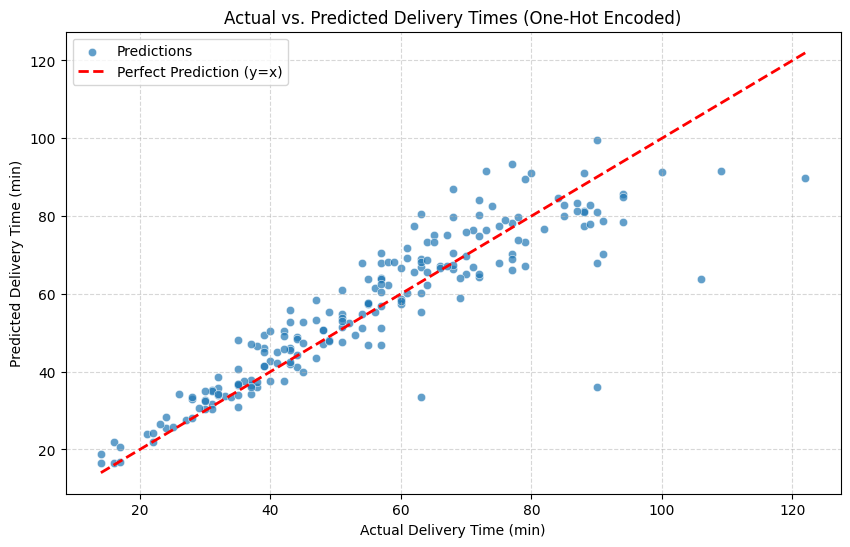

In [ ]:
plt.figure(figsize=(10, 6))
# Scatter plot comparing actual vs predicted values
sns.scatterplot(x=y2_test, y=y2_pred, alpha=0.7, label='Predictions')

# Add a diagonal reference line (y = x) representing perfect prediction
max_val = max(y2_test.max(), y2_pred.max())
min_val = min(y2_test.min(), y2_pred.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction (y=x)')

plt.xlabel('Actual Delivery Time (min)')
plt.ylabel('Predicted Delivery Time (min)')
plt.title('Actual vs. Predicted Delivery Times (One-Hot Encoded)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Ridge Regression
Train a Ridge regression model on the training data, predict delivery times for the test set, and evaluate its accuracy using MAE, MSE, and R².

In [ ]:
from sklearn.linear_model import Ridge,Lasso

ridge=Ridge()
ridge.fit(x2_train,y2_train)
y2_pred_ridge=ridge.predict(x2_test)
mean_squared_error(y2_test,y2_pred_ridge)
r2=r2_score(y2_test,y2_pred_ridge)
n=df.shape[0]
p=df.shape[1]
adjusted_r2=1-((1-r2)*(n-1))/(n-p-1)
r2

0.8194446507649069


### Lasso Regression
Train a Lasso regression model on your training data, predict delivery times for the test set, and check how accurate the predictions are using MAE, MSE, and R².

In [ ]:
lasso=Lasso()
lasso.fit(x2_train,y2_train)
y2_pred_lasso=lasso.predict(x2_test)
mean_squared_error(y2_test,y2_pred_lasso)
r2=r2_score(y2_test,y2_pred_lasso)
r2

0.7603136436652512

In [ ]:
df_copy.corr(numeric_only=True)

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
Order_ID,1.000000,-0.024483,-0.035100,0.012698,-0.036650
Distance_km,-0.024483,1.000000,-0.009037,-0.007534,0.780998
Preparation_Time_min,-0.035100,-0.009037,1.000000,-0.030842,0.307350
Courier_Experience_yrs,0.012698,-0.007534,-0.030842,1.000000,-0.089111
Delivery_Time_min,-0.036650,0.780998,0.307350,-0.089111,1.000000


<Axes: >

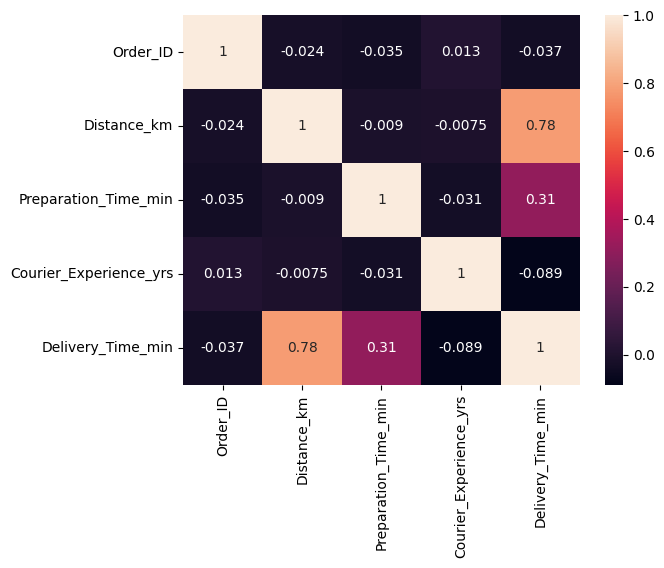

In [ ]:
sns.heatmap(df_copy.corr(numeric_only=True),annot=True)

### Polynomial Regression
Transform your features to include polynomial terms, train a Linear Regression model on them, and calculate the mean squared error to see how well the curved model fits your data.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=2)
x_train_poly=poly.fit_transform(x2_train)
x2_test_poly=poly.fit_transform(x2_test)
model_poly=LinearRegression()
model_poly.fit(x_train_poly,y2_train)
y2_pred_poly=model_poly.predict(x2_test_poly)

mse=mean_squared_error(y2_test,y2_pred_poly)
r2=r2_score(y2_test,y2_pred_poly)
r2

0.7842513160029416


# Conclusion
-Predicted food delivery times using features like distance, traffic, weather, time, and courier experience.

-Applied Linear Regression for basic predictions.

-Used Ridge and Lasso to reduce overfitting and improve accuracy.

-Explored Polynomial Regression to capture nonlinear relationships.

-Evaluated models with MAE, MSE, and R² to measure performance.

-Demonstrated a real-world application of regression in optimizing delivery operations.